## Importing materials

In [21]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt 
from scipy import stats

In [22]:
data = "kine2000_music_endurance_dataset.csv"
df = pd.read_csv(data)

# deleted empty/extra columns
df = df.drop(columns=[col for col in df.columns if "Unnamed" in col])

df.head()

,Participant (anonymous ID),Lab Section (Ex: Wed 2pm),Age (years),Height (m),Weight (kg),Silence Time to Failure (s),Music Time to Failure (s),Music Genre Selected
0,1,Thursday 10am,18,1.67,62.6,125.00,136.00,Pop
1,2,Thursday 10am,20,1.83,89.4,81.81,105.99,R&B
2,3,Thursday 10am,21,1.83,96.2,70.00,91.25,Alt. Metal
3,4,Thursday 10am,18,1.79,59.6,105.00,113.00,Pop
4,5,Thursday 10am,20,1.88,96.6,77.00,93.00,Pop


In [35]:
# adjusted the genre, specifcally for metal and alt. metal as the same group
df.loc[df['Music Genre Selected'] == 'Alt. Metal', 'Music Genre Selected'] = 'Metal'
df['Music Genre Selected']

0         Pop
1         R&B
2       Metal
3         Pop
4         Pop
5        Rock
6         Pop
7         Pop
8         Pop
9         Rap
10        Rap
11        Pop
12        Rap
13        Rap
14        R&B
15    Country
16    Hip Hop
17        R&B
18        Rap
19        Rap
20        Rap
21       Rock
22        Rap
23      Metal
24        Pop
25        Pop
26        Pop
Name: Music Genre Selected, dtype: str

## Bar graph comparing average wall-sit time between conditions

In [ ]:
condition_box = df[['Music Time to Failure (s)', 'Silence Time to Failure (s)']]
avg = condition_box.agg(['mean'])

plt.bar(
    ['Preferred Music', 'No Music'],
    [
        avg.loc['mean', 'Music Time to Failure (s)'],
        avg.loc['mean', 'Silence Time to Failure (s)']
    ]
)
plt.title("Average Time to Failure by Condition")
plt.ylabel("Average Time in Seconds (s)")
plt.show()

TypeError: Boolean array expected for the condition, not float64

In [38]:
summary = condition_box.agg(['mean', 'std'])
print(summary)

      Music Time to Failure (s)  Silence Time to Failure (s)
mean                 129.369630                    95.448889
std                   56.415308                    30.409065


## Paired dot plot of partricipants response

## Paired t-test comparing the two conditions

In [51]:
t_stat, p_value = stats.ttest_rel(
    df['Music Time to Failure (s)'],
    df['Silence Time to Failure (s)']
)

print(f"t = {t_stat:.3f}")
print(f"p = {p_value:.4f}")


t = 4.030
p = 0.0004


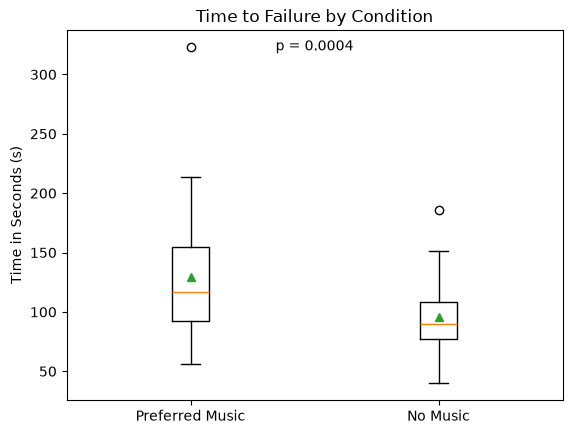

In [56]:
from scipy.stats import ttest_rel

t_stat, p_value = ttest_rel(
    df['Music Time to Failure (s)'],
    df['Silence Time to Failure (s)']
)

fig, ax = plt.subplots()

ax.boxplot(condition_box, tick_labels=['Preferred Music', 'No Music'], showmeans=True)

ax.set_title("Time to Failure by Condition")
ax.set_ylabel("Time in Seconds (s)")

ax.text(1.5, ax.get_ylim()[1] * 0.95, f"p = {p_value:.4f}", ha='center')

plt.show()
